# La prédiction des résultats d'entreprises cotées est-elle précise ? Et quelles sont les répercussions des erreurs d'anticipation sur les marchés ?
## Analyse Comparative : Données Réelles (SEC EDGAR), Projections (Alpha Vantage), Valeurs des actions (TIINGO)
**Entreprise étudiée :** Apple Inc. (AAPL - CIK: 0000320193)

### 0. Introduction

Actuellement étudiants à l'ENSAE en 2e année, nous sommes intéressés par le domaine financier et la place qu'ont les statistiques dans ce milieu. Comme la valorisation d'une entreprise dépend en grande partie de ses résultats, ces derniers sont soumis aux prédictions de nombreux experts. Nous avons souhaité mesurer la justesse de ces prédictions, et surtout l'impact d'une bonne (ou d'une mauvaise) surprise le jour de la publication des résultats.

Pour cela nous avons croisé trois tables de données venant de sources différentes :
- **Les résultats officiels des entreprises** déposés auprès du régulateur américain (**SEC EDGAR**).
- **Les prévisions et estimations de consensus** fournies par l'API financière **Alpha Vantage** (estimations moyennes des analystes financiers avant publication).
- **Les prix réels sur le marché** obtenus via l'API **TIINGO**, pour observer la variation des prix le jour de la publication des résultats.

Pour garder ce notebook synthétique et lisible, les fonctions techniques de requêtage, de nettoyage et de jointure sont encapsulées dans le module `fonctions.py`.

### 1. Importation des bibliothèques et période étudiée
Nous utilisons `pandas` et `numpy` pour la manipulation de données, `matplotlib` et `seaborn` pour les représentations graphiques, ainsi que notre module local `fonctions`.

#### Cadre de l'étude
Nous avons choisi d'étudier le cours d'Apple assez arbitrairement pour d'abord restreindre le champ d'étude à une unique entreprise comme preuve de concept. L'ensemble du notebook porte sur les **publications de résultats de janvier 2010** (`DATE_DEBUT_ECHANTILLON`) **à novembre 2026** (`DATE_FIN_ECHANTILLON`), soit le premier trimestre de l'exercice 2010 (clos fin décembre 2009) et les suivants. Avant 2010, le BPA d'Apple ne valait que quelques centimes (en base de titres actuelle) : un centime d'écart suffisait à produire des surprises extrêmes, de −50 % (1998, 2000) à +100 % (2004, 2006), et jusqu'à +118 % en 1996. Ces valeurs écraseraient à la fois les mesures d'erreur de la partie 5 et la régression de la partie 8.

La date de fin fige la période étudiée : si les données sont téléchargées à nouveau après de nouvelles publications d'Apple, les résultats (et les chiffres commentés dans ce notebook) restent identiques.

In [1]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Import du module fonctions.py
import fonctions

# Configuration de l'affichage
pd.set_option('display.max_columns', 15)
pd.set_option('display.precision', 3)
sns.set_theme(style="whitegrid")

# Période étudiée dans tout le notebook : résultats publiés entre ces deux dates (voir ci-dessus)
DATE_DEBUT_ECHANTILLON = '2010-01-01'
DATE_FIN_ECHANTILLON = '2026-11-30'
print("Importations réalisées avec succès !")

Importations réalisées avec succès !


### 2. Récupération et exploration des données réelles (SEC EDGAR)

L'API SEC EDGAR met à disposition l'intégralité des faits comptables (*Company Facts*) sous format JSON. Les données sont réparties en 3 taxonomies :
- **`dei`** (*Document & Entity Information*) : Métriques administratives (actions en circulation, flottant...).
- **`us-gaap`** : Plus de 500 grandeurs comptables (Chiffre d'affaires, Résultat net, Marges, Bénéfices par action...).
- **`ffd`** : Frais de dépôt (*filing fees*) versés à la SEC lors d'émissions de titres, sans intérêt pour notre étude.

Nous chargeons les données et les mettons en cache automatique dans `data_cache/` pour éviter de surcharger les serveurs de la SEC et rendre la suite du notebook plus fluide.

In [2]:
# Téléchargement et lecture du cache des faits comptables SEC d'Apple
sec_raw = fonctions.fetch_sec_data(cik="CIK0000320193")
facts = sec_raw['facts']

print(f"Entreprise : {sec_raw.get('entityName')} | CIK : {sec_raw.get('cik')}")
print("Taxonomies disponibles :", list(facts.keys()))
print(f"Nombre de métriques dans us-gaap : {len(facts['us-gaap'])}")
print(f"Nombre de métriques dans dei     : {len(facts['dei'])}")

Entreprise : Apple Inc. | CIK : 320193
Taxonomies disponibles : ['dei', 'us-gaap', 'ffd']
Nombre de métriques dans us-gaap : 512
Nombre de métriques dans dei     : 2


#### Extraction du Bénéfice Par Action (BPA) réel trimestriel
Les Bénéfices Par Action sont stockés dans la métrique `EarningsPerShareDiluted`. Nous l'extrayons en filtrant uniquement sur les périodes trimestrielles (~3 mois). Le quatrième trimestre n'est pas toujours publié en tant que tel : le rapport annuel (10-K) ne donne souvent que le BPA de l'exercice complet. Dans ce cas, nous reconstituons le T4 à partir du BPA annuel et des trois autres trimestres (T4 = BPA annuel − T1 − T2 − T3).

Une même période apparaît dans plusieurs dépôts (rapport d'origine, puis colonnes de comparaison des rapports suivants) : nous gardons la valeur du dépôt le plus récent. Les colonnes `form` et `filed` décrivent ce dépôt, tandis que `fy` (exercice) et `fp` (trimestre fiscal) sont recalculées à partir des dates de la période.

Nous ne gardons ensuite que les trimestres de la période étudiée. Apple publie ses résultats 3 à 5 semaines après la clôture du trimestre : les trimestres publiés à partir de janvier 2010 sont donc ceux clos à partir d'octobre 2009, et ceux publiés au plus tard fin novembre 2026 sont clos au moins un mois avant `DATE_FIN_ECHANTILLON`. Ce filtre est appliqué *après* la reconstitution des T4, qui a besoin des exercices complets.

In [3]:
# Extraction du BPA trimestriel, ajusté des divisions d'actions (base actuelle, comme Alpha Vantage)
# et complété des T4 que le 10-K ne publie pas (T4 = BPA annuel - T1 - T2 - T3)
df_sec_eps = fonctions.build_quarterly_eps(
    facts=facts,
    symbol="AAPL",
    metric_name='EarningsPerShareDiluted'
)

# Restriction à la période étudiée (les trimestres sont publiés 3 à 5 semaines après leur clôture) :
# - clos au plus 3 mois avant DATE_DEBUT_ECHANTILLON, donc publiés à partir de cette date ;
# - clos au moins 1 mois avant DATE_FIN_ECHANTILLON, donc publiés au plus tard à cette date.
debut_trimestres = pd.Timestamp(DATE_DEBUT_ECHANTILLON) - pd.DateOffset(months=3)
fin_trimestres = pd.Timestamp(DATE_FIN_ECHANTILLON) - pd.DateOffset(months=1)
df_sec_eps = df_sec_eps[df_sec_eps['end'].between(debut_trimestres, fin_trimestres)].reset_index(drop=True)

print(f"Nombre de trimestres SEC retenus : {len(df_sec_eps)} (dont {df_sec_eps['q4_derive'].sum()} T4 reconstitués), "
      f"clos du {df_sec_eps['end'].min():%d/%m/%Y} au {df_sec_eps['end'].max():%d/%m/%Y}")
print("\n--- Aperçu des dernières déclarations trimestrielles ---")
# 'form' / 'filed' : dépôt retenu (le plus récent) ; 'fy' / 'fp' : exercice et trimestre fiscal de la période
display(df_sec_eps[['end', 'fy', 'fp', 'val', 'val_brut', 'facteur_split', 'form', 'filed', 'q4_derive']].tail(5))

print("\n--- Vérification des cellules vides ---")
print(df_sec_eps.drop(columns=['val_brut', 'frame']).isnull().sum())  # val_brut/frame vides pour les T4 reconstitués

Nombre de trimestres SEC retenus : 68 (dont 6 T4 reconstitués), clos du 26/12/2009 au 26/09/2026

--- Aperçu des dernières déclarations trimestrielles ---


,end,fy,fp,val,val_brut,facteur_split,form,filed,q4_derive
63,2025-09-27,2025,Q4,1.84,NaN,1.0,10-K (T4 dérivé),2026-11-03,True
64,2025-12-27,2026,Q1,2.84,2.84,1.0,10-Q,2026-01-30,False
65,2026-03-28,2026,Q2,2.01,2.01,1.0,10-Q,2026-05-01,False
66,2026-06-27,2026,Q3,2.02,2.02,1.0,10-Q,2026-07-31,False
67,2026-09-26,2026,Q4,2.11,NaN,1.0,10-K (T4 dérivé),2026-11-03,True



--- Vérification des cellules vides ---
start            0
end              0
val              0
accn             0
fy               0
fp               0
form             0
filed            0
duration_days    0
metric_name      0
facteur_split    0
q4_derive        0
dtype: int64


### 3. Récupération et exploration des projections (Alpha Vantage)

L'API **Alpha Vantage** fournit via `EARNINGS` les quatre métriques suivantes :
- **`estimatedEPS`** : Le consensus prévisionnel des analystes.
- **`reportedEPS`** : Le résultat réel publié par Apple.
- **`surprise`** : L'écart absolu (Réel - Prévision).
- **`surprisePercentage`** : L'écart relatif en pourcentage.


> **Note sur les requêtes API** : L'API gratuite d'Alpha Vantage ne permet que 25 requêtes par jour. Notre proxy Vercel, qui détient les clés d'API, limite donc chaque utilisateur à 5 requêtes par jour (par adresse IP). Cette limite est indicative : le compteur est conservé en mémoire par le serveur et repart de zéro à chaque redémarrage de celui-ci. En pratique, le cache local `data_cache/` évite de refaire les requêtes à chaque exécution du notebook.

In [4]:
# Récupération des données Alpha Vantage et stockage dans le cache local data_cache/
df_av_complet = fonctions.fetch_alphavantage_earnings(symbol="AAPL")

print(f"Nombre de trimestres Alpha Vantage obtenus : {len(df_av_complet)} "
      f"(publiés du {df_av_complet['reportedDate'].min():%d/%m/%Y} au {df_av_complet['reportedDate'].max():%d/%m/%Y})")
print("\n--- Aperçu des projections Alpha Vantage ---")

# Affichage des colonnes d'intérêt pour les 5 derniers trimestres
display(df_av_complet[['fiscalDateEnding', 'reportedDate', 'reportedEPS', 'estimatedEPS', 'surprise', 'surprisePercentage']].head(5))

Nombre de trimestres Alpha Vantage obtenus : 123 (publiés du 17/04/1996 au 02/11/2026)

--- Aperçu des projections Alpha Vantage ---


,fiscalDateEnding,reportedDate,reportedEPS,estimatedEPS,surprise,surprisePercentage
0,2026-09-30,2026-11-02,2.05,1.98,0.07,3.535
1,2026-06-30,2026-07-30,2.02,1.88,0.14,7.447
2,2026-03-31,2026-04-30,2.01,1.94,0.07,3.608
3,2025-12-31,2026-01-29,2.84,2.67,0.17,6.367
4,2025-09-30,2025-10-30,1.85,1.77,0.08,4.520


Avant d'utiliser ces métriques, nous souhaitons savoir si elles sont représentatives, c'est-à-dire si elles possèdent suffisamment de données non vides pour être exploitées.

In [5]:
print("\n--- Types et cellules vides (historique complet) ---")
print(df_av_complet[['reportedEPS', 'estimatedEPS', 'surprise']].info())

sans_estimation = df_av_complet[df_av_complet['estimatedEPS'].isna()]
print(f"\nTrimestres sans estimation : {len(sans_estimation)}, publiés entre "
      f"{sans_estimation['reportedDate'].min():%Y} et {sans_estimation['reportedDate'].max():%Y}")

# Restriction à la période étudiée (publications entre DATE_DEBUT_ECHANTILLON et DATE_FIN_ECHANTILLON)
df_av = df_av_complet[df_av_complet['reportedDate'].between(DATE_DEBUT_ECHANTILLON, DATE_FIN_ECHANTILLON)].reset_index(drop=True)
print(f"\nTrimestres retenus sur la période étudiée : {len(df_av)}, "
      f"dont {df_av['estimatedEPS'].isna().sum()} sans estimation")


--- Types et cellules vides (historique complet) ---
<class 'pandas.DataFrame'>
RangeIndex: 123 entries, 0 to 122
Data columns (total 3 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   reportedEPS   123 non-null    float64
 1   estimatedEPS  113 non-null    float64
 2   surprise      113 non-null    float64
dtypes: float64(3)
memory usage: 3.0 KB
None

Trimestres sans estimation : 10, publiés entre 1997 et 2003

Trimestres retenus sur la période étudiée : 68, dont 0 sans estimation


Sur les 123 trimestres fournis par Alpha Vantage lors de notre téléchargement (novembre 2026), 10 ne possèdent pas d'estimation de BPA (~ 8 % de cellules vides). Ils ont tous été publiés entre 1997 et 2003, donc **avant la période étudiée** : une fois l'échantillon restreint aux publications depuis 2010, il ne reste aucune cellule vide et aucun trimestre n'a besoin d'être supprimé.

### 4. Rapprochement temporel : jointure entre résultats et prédictions

Pour comparer les résultats réels (SEC) aux prédictions (Alpha Vantage), nous souhaitons joindre les tables par trimestres. Cependant nous avons rencontré l'obstacle suivant : 
- Apple clôture son exercice comptable le dernier samedi de septembre (ex: 28 septembre pour l'exercice 2024 dans le rapport 10-K de la SEC).
- Alpha Vantage arrondit conventionnellement la fin de trimestre au dernier jour calendaire du mois (ex: 30 septembre).

Pour dépasser ce problème, nous réalisons une jointure temporelle asynchrone avec **`pd.merge_asof`** en permettant une tolérance de 7 jours pour apparier rigoureusement chaque trimestre.

In [6]:
# Jointure des deux dataframes sur la date de fin de trimestre (sec_date = fiscalDateEnding)
comparison = fonctions.compare_real_vs_projections(df_sec_eps, df_av)

# Affichage des résultats de la comparaison
print(f"Nombre total de trimestres appariés : {len(comparison)} "
      f"(publiés du {comparison['reportedDate'].min():%d/%m/%Y} au {comparison['reportedDate'].max():%d/%m/%Y})")
print("\n--- Échantillon des 5 derniers trimestres comparés ---")
cols_display = ['sec_date', 'sec_real_eps', 'estimatedEPS', 'forecast_error', 'forecast_pct_error', 'beat_projection']
display(comparison[cols_display].tail(5))

# Contrôle de cohérence : BPA réel SEC vs BPA réel retenu par Alpha Vantage (reportedEPS)
ecart_sources = (comparison['sec_real_eps'] - comparison['reportedEPS']).round(2)
print(f"\nÉcart SEC - Alpha Vantage sur le BPA réel : au plus {ecart_sources.abs().max():.2f} $, "
      f"{(ecart_sources.abs() > 0.01).sum()} trimestre(s) au-delà de 1 centime :")
display(comparison.loc[ecart_sources.abs() > 0.01,
                       ['sec_date', 'fy', 'fp', 'q4_derive', 'sec_real_eps', 'reportedEPS', 'estimatedEPS']])

Nombre total de trimestres appariés : 68 (publiés du 25/01/2010 au 02/11/2026)

--- Échantillon des 5 derniers trimestres comparés ---


,sec_date,sec_real_eps,estimatedEPS,forecast_error,forecast_pct_error,beat_projection
63,2025-09-27,1.84,1.77,0.07,3.955,True
64,2025-12-27,2.84,2.67,0.17,6.367,True
65,2026-03-28,2.01,1.94,0.07,3.608,True
66,2026-06-27,2.02,1.88,0.14,7.447,True
67,2026-09-26,2.11,1.98,0.13,6.566,True



Écart SEC - Alpha Vantage sur le BPA réel : au plus 0.06 $, 1 trimestre(s) au-delà de 1 centime :


,sec_date,fy,fp,q4_derive,sec_real_eps,reportedEPS,estimatedEPS
67,2026-09-26,2026,Q4,True,2.11,2.05,1.98


Les deux sources concordent : le BPA réel de la SEC et celui retenu par Alpha Vantage sont égaux au centime près, à une exception : le T4 de l'exercice 2026 (2,11 \$ côté SEC contre 2,05 \$ côté Alpha Vantage). Ce trimestre est reconstitué (BPA annuel − T1 − T2 − T3). Or les deux sources s'accordent sur T1, T2 et T3, et sur les exercices où les quatre trimestres sont publiés, la somme des trimestres ne s'écarte que d'un centime au plus du BPA annuel. L'écart vient donc d'un désaccord entre le BPA annuel du rapport 10-K (8,98 \$) et les données d'Alpha Vantage. Nous retenons la valeur SEC, issue du rapport officiel : cela ne change pas le sens de la surprise (positive dans les deux cas).

### 5. Analyse statistique de la qualité des projections

Nous calculons les métriques standards d'évaluation des prévisions en économétrie financière :
- **MAE (Mean Absolute Error)** : $\frac{1}{n} \sum |e_t|$
- **RMSE (Root Mean Squared Error)** : $\sqrt{\frac{1}{n} \sum e_t^2}$
- **Biais Moyen** : $\frac{1}{n} \sum e_t$ (un biais positif indique que les prévisions sous-estiment systématiquement la réalité)
- **MAPE (Mean Absolute Percentage Error)** : Erreur moyenne en pourcentage
- **Taux de surprise positive** : Pourcentage des trimestres où le réel dépasse le consensus des analystes.

> **Note sur les divisions d'actions (Stock Splits) :**
> Apple a procédé à une division d'actions par 4 en août 2020 (et par 7 en 2014). Les rapports SEC publient le BPA dans la base de titres en vigueur à la date du dépôt : `build_quarterly_eps` divise donc chaque valeur par les divisions postérieures à son dépôt (dates issues de Tiingo), ce qui rend toute la période comparable aux estimations Alpha Vantage. Nous présentons aussi séparément les trimestres avant et après la division de 2020.

In [7]:
def libelle_periode(nom, df):
    return f"{nom} ({df['reportedDate'].min():%m/%Y} → {df['reportedDate'].max():%m/%Y})"

# Découpage autour de la division d'actions du 31 août 2020, selon la date de publication des résultats
DATE_SPLIT_2020 = '2020-08-31'
comparison_avant = comparison[comparison['reportedDate'] < DATE_SPLIT_2020].copy()
comparison_recent = comparison[comparison['reportedDate'] >= DATE_SPLIT_2020].copy()

summary_table = pd.DataFrame([
    {"Période": libelle_periode("Période étudiée", comparison), **fonctions.compute_forecast_metrics(comparison)},
    {"Période": libelle_periode("Avant le split de 2020", comparison_avant), **fonctions.compute_forecast_metrics(comparison_avant)},
    {"Période": libelle_periode("Depuis le split de 2020", comparison_recent), **fonctions.compute_forecast_metrics(comparison_recent)},
]).set_index("Période")

display(summary_table)

,N_Observations,MAE (USD/action),RMSE (USD/action),Biais Moyen (USD/action),MAPE (%),Taux Surprise Positive (%)
Période,,,,,,
Période étudiée (01/2010 → 11/2026),68,0.062,0.096,0.058,9.80,91.18
Avant le split de 2020 (01/2010 → 07/2020),43,0.036,0.050,0.033,10.98,90.70
Depuis le split de 2020 (10/2020 → 11/2026),25,0.107,0.144,0.101,7.75,92.00


Une fois le BPA ajusté des divisions d'actions et les T4 reconstitués, les prévisions des analystes sont **très proches de la réalité** : sur la période étudiée, l'erreur moyenne absolue (**MAE**) n'est que de *0,06 \$* par action. Le **Biais Moyen** reste toutefois positif (*+0,058 \$*) et le **Taux de Surprise Positive** atteint *91,2 %* : les analystes sous-estiment presque systématiquement les résultats d'Apple.

Depuis le split de 2020, la **MAE** (*0,11 \$*) et le **RMSE** (*0,14 \$*) sont plus élevés qu'avant (*0,04 \$* et *0,05 \$*). Ce n'est pas une baisse de précision : le BPA d'Apple a fortement augmenté (de ~0,13 \$ par trimestre en 2010 à plus de 2 \$ aujourd'hui), donc une même erreur relative représente plus de dollars. Rapportée au niveau du BPA, l'erreur diminue : le **MAPE** passe de *11,0 %* avant 2020 à *7,8 %* depuis.

Le taux de surprise positive est en revanche stable (*90,7 %* avant 2020, *92,0 %* depuis) : la sous-estimation par les analystes est un phénomène durable, et non propre à une période.

### 6. Visualisations Graphiques

Les graphiques s'appuient sur `comparison`, construit à partir de `build_quarterly_eps` : chaque point est un **trimestre** de la période étudiée (BPA ajusté des divisions d'actions, T4 reconstitué à partir du BPA annuel).

#### A. Évolution temporelle : BPA Réel vs Consensus des Analystes

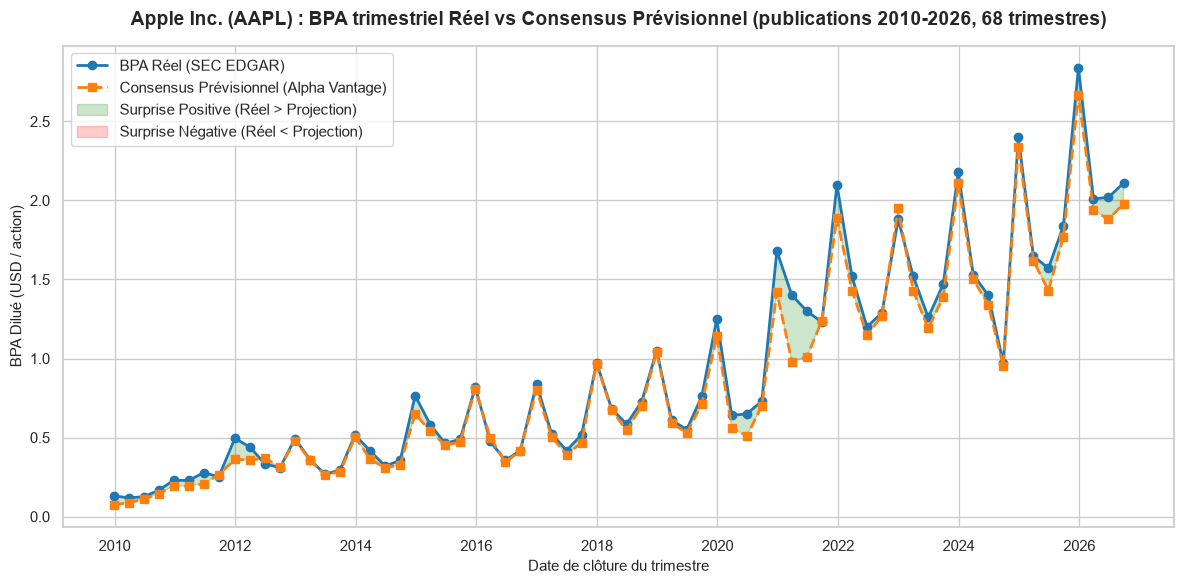

In [8]:
# Graphique chronologique Réel vs Prévisionnel (un point par trimestre de la période étudiée)
fonctions.plot_real_vs_projected(comparison)

#### B. Distribution des erreurs de prévision (*Earnings Surprises*)

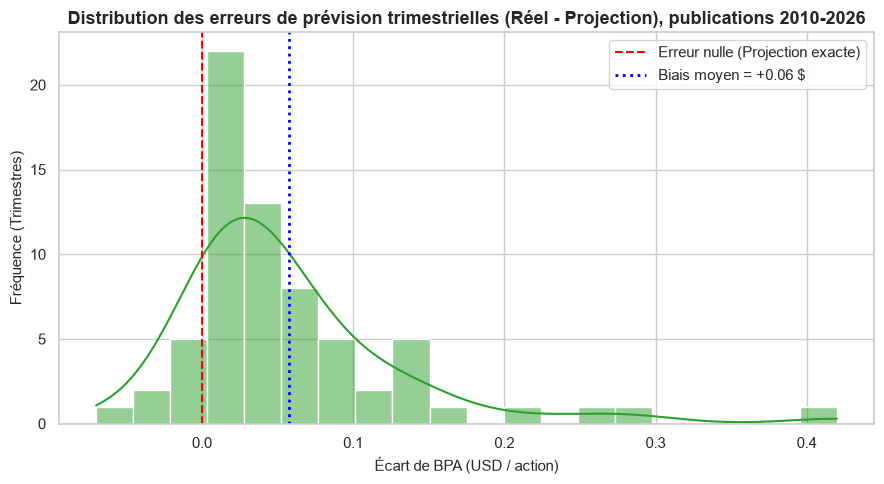

In [9]:
# Distribution de l'erreur Réel - Projection (trimestres de la période étudiée)
fonctions.plot_error_distribution(comparison)

#### Quelques interprétations

Les graphiques et le tableau ci-dessus mettent en évidence deux grandes tendances :
- D'une part, la **précision remarquable du consensus post-2020**. En effet d'après le tableau récapitulatif, l'erreur moyenne absolue (**MAE**) est d'environ **0,11 \$ par action**, pour une erreur moyenne en pourcentage (**MAPE**) inférieure à **8 %**, donc assez proche de la réalité.
- D'autre part, le graphique B permet de visualiser le **Biais de prudence systématique des analystes**. De fait, le biais moyen est positif (+0,10 \$ depuis 2020), indiquant que les analystes ont tendance à sous-estimer légèrement les performances réelles d'Apple ; et le **taux de surprise positive s'élève à près de 92 %** ! Apple dépasse quasi-systématiquement les attentes du marché. On retrouve donc dans ces données une stratégie classique de communication financière (*under-promising and over-delivering*).

### 7. L'impact de la surprise sur la valorisation des actions

Maintenant que nous avons évalué les biais et les tendances des prédictions par rapport aux valeurs réelles du marché, nous allons mesurer les conséquences de la surprise sur le prix des actions lors de la révélation des résultats réels.

Pour cela, nous récupérons les cotations quotidiennes des actions Apple grâce à l'**API TIINGO**.

In [10]:
# Récupération des cours quotidiens AAPL en les stockant dans le cache local data_cache/
df_prices = fonctions.fetch_tiingo_prices(symbol="AAPL")

# Affichage des 5 dernières séances
print(f"Nombre de séances : {len(df_prices)} ({df_prices['date'].min():%d/%m/%Y} → {df_prices['date'].max():%d/%m/%Y})")
display(df_prices[['date', 'close', 'adjClose', 'splitFactor', 'divCash']].tail(5))

Nombre de séances : 6763 (03/01/2000 → 20/11/2026)


,date,close,adjClose,splitFactor,divCash
6758,2026-11-16,352.78,352.78,1.0,0.0
6759,2026-11-17,351.91,351.91,1.0,0.0
6760,2026-11-18,352.45,352.45,1.0,0.0
6761,2026-11-19,349.21,349.21,1.0,0.0
6762,2026-11-20,342.56,342.56,1.0,0.0


#### Cours avant et après chaque publication (fenêtre J → J+1)

Apple publie ses résultats **après la clôture** de la bourse le jour J (`reportedDate` d'Alpha Vantage). Pour estimer l'impact des résultats sur les prix nous utilisons donc :
- **clôture de J** = dernier prix *avant* l'information ;
- **clôture de J+1** = premier prix *après* l'information (séance de bourse suivante).

Nous apparions les deux prix avec `pd.merge_asof` (dernière séance ≤ J, première séance > J). La variation est calculée sur `adjClose` pour rester juste si un détachement de dividende ou une division d'actions tombe dans la fenêtre.

In [11]:
# Cours de clôture J et J+1 pour chaque publication de résultats de la période étudiée
reaction = fonctions.compute_announcement_price_reaction(df_av, df_prices)

print(f"Publications avec cours J et J+1 disponibles : {len(reaction)}")
print(f"Publications dont J n'est pas un jour de bourse : {(~reaction['J_jour_de_bourse']).sum()}")

cols_reaction = ['fiscalDateEnding', 'reportedDate', 'date_J1', 'close_J', 'close_J1',
                 'adjClose_J', 'adjClose_J1', 'variation_pct', 'surprisePercentage']
print("\n--- 8 dernières publications ---")
display(reaction[cols_reaction].tail(8))

print("\n--- Statistiques de la variation J -> J+1 (%) ---")
display(reaction['variation_pct'].describe())

Publications avec cours J et J+1 disponibles : 68
Publications dont J n'est pas un jour de bourse : 0

--- 8 dernières publications ---


,fiscalDateEnding,reportedDate,date_J1,close_J,close_J1,adjClose_J,adjClose_J1,variation_pct,surprisePercentage
60,2024-12-31,2025-01-30,2025-01-31,237.59,236.00,235.710,234.133,-0.669,2.564
61,2025-03-31,2025-05-01,2025-05-02,213.32,205.35,211.865,203.949,-3.736,1.852
62,2025-06-30,2025-07-31,2025-08-01,207.57,202.38,206.408,201.247,-2.500,9.790
63,2025-09-30,2025-10-30,2025-10-31,271.40,270.37,270.190,269.164,-0.380,4.520
64,2025-12-31,2026-01-29,2026-01-30,258.28,259.48,257.376,258.572,0.465,6.367
65,2026-03-31,2026-04-30,2026-05-01,271.35,280.14,270.657,279.424,3.239,3.608
66,2026-06-30,2026-07-30,2026-07-31,333.43,308.91,332.885,308.405,-7.354,7.447
67,2026-09-30,2026-11-02,2026-11-03,338.32,331.90,338.063,331.648,-1.898,3.535



--- Statistiques de la variation J -> J+1 (%) ---


count    68.000
mean      0.599
std       4.684
min     -12.355
25%      -2.493
50%       0.195
75%       4.486
max      10.469
Name: variation_pct, dtype: float64

### 8. Régression de la variation du cours sur la surprise de BPA

Pour mesurer l'impact de la surprise sur les prix, nous posons le modèle suivant et estimons les coefficients par la méthode des moindres carrés ordinaires (MCO), calculés avec `numpy` :

$$\text{variation}_t = \alpha + \beta \cdot \text{surprise}_t + \varepsilon_t$$

- **variation** : variation du cours ajusté entre la clôture de J et celle de J+1 (en %) ;
- **surprise** : écart entre le BPA réel et le consensus, en % du consensus (`surprisePercentage`) ;
- **β** : de combien de points de % le cours varie en moyenne pour 1 point de surprise supplémentaire.

Pour obtenir une régression linéaire cohérente, nous avons fait les **choix méthodologiques** suivants :
- **Échantillon depuis 2010** : comme dans tout le notebook, seules les publications à partir de janvier 2010 sont retenues (voir la partie 1) ; avant, les surprises extrêmes écraseraient la régression.
- **Écarts-types robustes** : la dispersion des variations n'a aucune raison d'être la même pour toutes les surprises ; les tests reposent donc sur ces écarts-types. Les écarts-types classiques sont affichés pour comparaison.
- **p-values approchées par la loi normale** : comme nous avons près de 70 observations, l'écart avec la loi de Student est négligeable.

In [12]:
# Régression MCO de la variation du cours sur la surprise de BPA (période étudiée)
coef_reg, stats_reg, sample_reg = fonctions.regress_price_on_surprise(reaction, start_date=DATE_DEBUT_ECHANTILLON)

display(pd.DataFrame([stats_reg]).set_index('Période'))
display(coef_reg.round(4))

beta = coef_reg['coefficient'].iloc[1]
print(f"Lecture : 1 point de surprise en plus est associé à une variation de {beta:+.3f} point de % du cours à J+1.")

# Les 5 observations les plus influentes (plus fortes surprises en valeur absolue)
print("\n--- Plus fortes surprises de l'échantillon ---")
display(sample_reg.reindex(sample_reg['surprisePercentage'].abs().sort_values(ascending=False).index)
        [['reportedDate', 'reportedEPS', 'estimatedEPS', 'surprisePercentage', 'variation_pct']].head(5))

,N_Observations,R2,R2_ajusté,Corrélation,Écart-type des résidus (pts de %)
Période,,,,,
01/2010 → 11/2026,68,0.074,0.06,0.272,4.541


,coefficient,ecart_type_classique,ecart_type_robuste_HC1,t_robuste,p_value,IC95_bas,IC95_haut
constante (alpha),-0.291,0.673,0.688,-0.423,0.672,-1.639,1.057
surprisePercentage (beta),0.099,0.043,0.045,2.188,0.029,0.010,0.187


Lecture : 1 point de surprise en plus est associé à une variation de +0.099 point de % du cours à J+1.

--- Plus fortes surprises de l'échantillon ---


,reportedDate,reportedEPS,estimatedEPS,surprisePercentage,variation_pct
0,2010-01-25,0.130,0.075,73.333,1.411
45,2021-04-28,1.400,0.980,42.857,-0.075
1,2010-04-20,0.120,0.087,37.143,5.981
8,2012-01-24,0.495,0.362,36.552,6.244
6,2011-07-19,0.278,0.207,33.735,2.667


On remarque dans le tableau ci-dessus que la publication de janvier 2010 (surprise d'environ +73 %) est une valeur extrême de notre échantillon. Elle risque d'avoir un poids anormalement élevé dans la régression.

Vérifions que nos conclusions n'en dépendent pas, en ré-estimant le modèle sans cette publication, puis sans toutes les surprises supérieures à 30 % en valeur absolue. Nous mesurons enfin la surprise avec le BPA SEC de la partie 5 (`forecast_pct_error`) plutôt qu'avec celui d'Alpha Vantage, pour vérifier la cohérence des deux parties.

In [13]:
# Robustesse de la régression : mêmes estimations sur des échantillons ou des mesures de surprise différents
reaction_sec = reaction.merge(comparison[['reportedDate', 'forecast_pct_error']], on='reportedDate')
variantes = {
    "Échantillon complet": (reaction, 'surprisePercentage'),
    "Sans la plus forte surprise (01/2010)": (reaction.drop(reaction['surprisePercentage'].idxmax()), 'surprisePercentage'),
    "Surprises inférieures à 30 % en valeur absolue": (reaction[reaction['surprisePercentage'].abs() < 30], 'surprisePercentage'),
    "Surprise calculée avec le BPA SEC": (reaction_sec, 'forecast_pct_error'),
}

lignes = []
for nom, (donnees, x_col) in variantes.items():
    coef, stats, _ = fonctions.regress_price_on_surprise(donnees, x_col=x_col, start_date=DATE_DEBUT_ECHANTILLON)
    lignes.append({"Échantillon": nom, "N_Observations": stats['N_Observations'],
                   "beta": coef['coefficient'].iloc[1], "p_value (robuste)": coef['p_value'].iloc[1],
                   "R2": stats['R2']})
display(pd.DataFrame(lignes).set_index("Échantillon").round(3))

,N_Observations,beta,p_value (robuste),R2
Échantillon,,,,
Échantillon complet,68,0.099,0.029,0.074
Sans la plus forte surprise (01/2010),67,0.150,0.003,0.107
Surprises inférieures à 30 % en valeur absolue,63,0.209,0.014,0.101
Surprise calculée avec le BPA SEC,68,0.096,0.032,0.071


Écarter la publication de janvier 2010 ne fait pas disparaître la relation, au contraire : β passe de 0,099 à 0,150 (p = 0,003). Cette observation atypique (très forte surprise, réaction du cours modeste) tirait donc la pente vers le bas. Le résultat est le même en excluant toutes les surprises de plus de 30 % (β = 0,21, p = 0,014). Enfin, mesurer la surprise avec le BPA SEC plutôt qu'avec celui d'Alpha Vantage donne un résultat quasi identique (β = 0,096) : les parties 5 et 8 sont cohérentes.

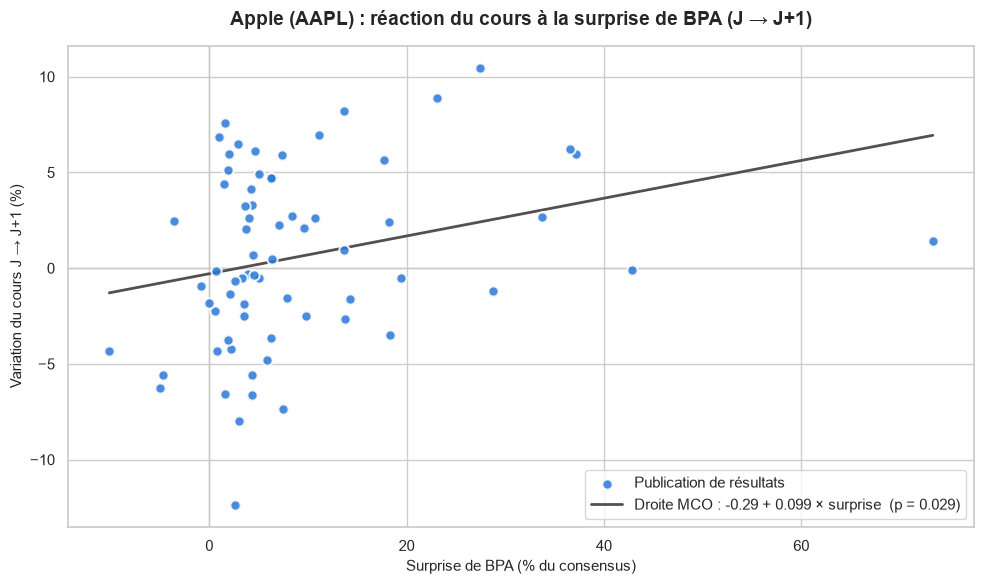

In [14]:
# Nuage de points et droite de régression
fonctions.plot_price_vs_surprise(sample_reg, coef_reg)

La droite de régression met en évidence une relation positive entre la surprise et la variation du cours : comme on pouvait s'y attendre, une bonne surprise s'accompagne en moyenne d'une hausse du cours le lendemain de la publication. Le coefficient β est significatif au seuil de 5 % (p ≈ 0,03), et il le reste, voire se renforce, lorsque l'on écarte les surprises extrêmes.

L'effet reste toutefois modeste et le nuage de points très dispersé :
- Le **R²** n'est que d'environ 7 % : plus de 90 % de la variation du cours le jour des résultats s'explique par autre chose que la surprise sur le BPA (chiffre d'affaires, prévisions de la direction pour le trimestre suivant, contexte de marché...).
- Pour une surprise de 5 %, typique chez Apple, le modèle prévoit une variation d'environ −0,29 + 0,099 × 5 ≈ +0,2 point de %, très faible devant l'écart-type des résidus (environ 4,5 points).
- La constante α n'est pas significativement différente de 0 : une publication conforme au consensus n'entraîne pas de variation particulière du cours.

### 9. Principales conclusions & Interprétation Économique

1. **Des prévisions précises** :
   - Sur 2010-2026, l'erreur moyenne absolue (**MAE**) n'est que de **0,06 \$ par action**. Depuis 2020, elle est d'environ **0,11 \$**, pour un BPA bien plus élevé : l'erreur moyenne en pourcentage (**MAPE**) est inférieure à **8 %** (contre 11,0 % avant 2020).
2. **Biais de prudence systématique des analystes** :
   - Le biais moyen est positif (+0,06 \$ sur 2010-2026, +0,10 \$ depuis 2020), indiquant que les analystes ont tendance à sous-estimer légèrement les performances réelles d'Apple.
   - Le **taux de surprise positive s'élève à près de 91 %**, avant comme après 2020 : Apple dépasse quasi-systématiquement les attentes du marché, une stratégie classique de communication financière (*under-promising and over-delivering*).
3. **Une réaction du marché réelle mais modeste** :
   - Chaque point de surprise supplémentaire est associé à une hausse moyenne d'environ **0,1 point de %** du cours le lendemain de la publication. Ce coefficient est significatif au seuil de 5 % et robuste à l'exclusion des surprises extrêmes.
   - La surprise sur le BPA n'explique cependant qu'environ **7 %** de la variation du cours (R²) : le marché réagit surtout à d'autres informations publiées le même jour.
4. **Démarche et limites** :
   - Les données comptables officielles (SEC XBRL) sont confrontées au consensus (Alpha Vantage) et aux cours de bourse (Tiingo) via `pd.merge_asof`, sur une période figée (2010-2026) : la chaîne de traitement est reproductible.
   - Une seule entreprise est étudiée : ces résultats ne se généralisent pas nécessairement à d'autres entreprises.
   - Les BPA de la SEC sont ceux du dépôt le plus récent (éventuellement retraités), et non forcément ceux connus le jour de la publication ; les T4 reconstitués sont une approximation (écart de 6 centimes avec Alpha Vantage pour le T4 2026).